In [1]:
import json
import argparse
import tqdm
import time
import textstat
import os

import re
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import prettytable
from prettytable import PrettyTable
from scipy.stats import spearmanr, pearsonr, kendalltau


In [2]:
summeval_fp = '/users/data/summeval.json'
prompt_fp1 = '/users/prompts/summeval/coh_detailed.txt'
prompt_fp1 = '/users/prompts/summeval/rel_detailed.txt'
save_fp = '/users/results/gpt4_con_detailed_openai.json'

input_fp_rel = '/users/results/gpt4_rel_detailed.json'
input_fp_con = '/users/results/gpt4_con_detailed.json'

saving_path = '/users/results/figures'

In [3]:
def parse_output(output):
    matched = re.search("^ ?([\d\.]+)", output)
    if (matched):
        try:
            score = float(matched.group(1))
        except:
            score = 0
    else:
        score = 0
    return score

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_2438605/2072338213.py:2: SyntaxWarning: invalid escape sequence '\d'
  matched = re.search("^ ?([\d\.]+)", output)


In [84]:
save_dir = '/users/results'

file_path = os.path.join(save_dir, 'output_dicts_readablity_scores_rel.pkl')
# rel_dicts = [model_scores_rel, human_scores_rel, red_scores_rel]

with open(file_path, 'rb') as f:
   [model_scores_rel, human_scores_rel, red_scores_rel] = pickle.load(f)

file_path = os.path.join(save_dir, 'output_dicts_readablity_scores_coh.pkl')
# rel_dicts = [model_scores_coh, human_scores_coh, red_scores_coh]

with open(file_path, 'rb') as f:
    [model_scores_coh, human_scores_coh, red_scores_coh] = pickle.load(f)



In [86]:
from scipy.stats import pearsonr

def find_readability_correlations(
    model_scores_rel, human_scores_rel, red_scores_rel,
    model_scores_con, human_scores_con, red_scores_con,
    model_scores_coh, human_scores_coh, red_scores_coh,
    model_scores_flu, human_scores_flu, red_scores_flu,
    readability_measure='flesch_reading_ease'
):
    results_p = []
    results_s = []
    results_t = []

    dims = {
        'relevance': (model_scores_rel, human_scores_rel, red_scores_rel),
        'consistency': (model_scores_con, human_scores_con, red_scores_con),
        'coherence': (model_scores_coh, human_scores_coh, red_scores_coh),
        'fluency':   (model_scores_flu, human_scores_flu, red_scores_flu)
    }

    for dim_name, (model_scores, human_scores, red_scores) in dims.items():
        red_vals, human_vals, model_vals = [], [], []

        for doc_id in red_scores:
            r_list = red_scores[doc_id]
            h_list = human_scores.get(doc_id, [])
            m_list = model_scores.get(doc_id, [])

            if not (len(r_list) == len(h_list) == len(m_list)):
                continue

            for i in range(len(r_list)):
                r_val = r_list[i].get(readability_measure)
                if r_val is None:
                    continue
                red_vals.append(r_val)
                human_vals.append(h_list[i])
                model_vals.append(m_list[i])
        # print('len',len(red_vals))
        
        if len(red_vals) < 2:
            continue  # skip if too little data for correlation

        # Compute correlations
        # corr_h, pval_h = pearsonr(red_vals, human_vals)
        # corr_m, pval_m = pearsonr(red_vals, model_vals)

        corrp_human, pvalp_human = pearsonr(red_vals, human_vals)
        corrp_model, pvalp_model = pearsonr(red_vals, model_vals)
    
        
        corrs_human, pvals_human = spearmanr(red_vals, human_vals)
        corrs_model, pvals_model = spearmanr(red_vals, model_vals)
    
        tau_human,pvalt_human = kendalltau(red_vals, human_vals)
        tau_model,pvalt_model = kendalltau(red_vals, model_vals)

    
        # Collect all correlations
        results_p.append((dim_name, 'human', corrp_human, pvalp_human))
        results_p.append((dim_name, 'model', corrp_model, pvalp_model))
        
        results_s.append((dim_name, 'human', corrs_human, pvals_human))
        results_s.append((dim_name, 'model', corrs_model, pvals_model))
        
        results_t.append((dim_name, 'human', tau_human, pvalt_human))
        results_t.append((dim_name, 'model', tau_model, pvalt_model))
        
    return results_p,results_s,results_t


In [ ]:
inp_out_metrics = [
    'flesch_reading_ease',
    'flesch_kincaid_grade',
    'gunning_fog',
    'smog_index',
    'dale_chall_score',
    'difficult_words',
    'lexicon_count',
    'syllable_count',
    'cosine_sim'
]

In [87]:
readability_metrics = [
    'flesch_reading_ease',
    'flesch_kincaid_grade',
    'gunning_fog',
    'smog_index',
    'dale_chall_score',
    'difficult_words',
    'lexicon_count',
    'syllable_count'
]

In [88]:
for metric in readability_metrics:
    
    all_corrs = find_readability_correlations(
        model_scores_rel, human_scores_rel, red_scores_rel,
        model_scores_con, human_scores_con, red_scores_con,
        model_scores_coh, human_scores_coh, red_scores_coh,
        model_scores_flu, human_scores_flu, red_scores_flu,
        readability_measure=metric
    )

In [89]:
# Map metrics to x-locations
metric_indices = {metric: i for i, metric in enumerate(readability_metrics)}


In [90]:
all_results_p = []
all_results_s = []
all_results_t = []

for metric in readability_metrics:
    corrs = find_readability_correlations(
        model_scores_rel, human_scores_rel, red_scores_rel,
        model_scores_con, human_scores_con, red_scores_con,
        model_scores_coh, human_scores_coh, red_scores_coh,
        model_scores_flu, human_scores_flu, red_scores_flu,      
        readability_measure = metric
    )
    corrs_p,corrs_s,corrs_t = corrs

    for dim, score_type, corr, p in corrs_p:
        all_results_p.append({
            "metric": metric,
            "dimension": dim,
            "score_type": score_type,
            "correlation": corr,
            "p_value": p
        })
    for dim, score_type, corr, p in corrs_s:
        all_results_s.append({
            "metric": metric,
            "dimension": dim,
            "score_type": score_type,
            "correlation": corr,
            "p_value": p
        })
    for dim, score_type, corr, p in corrs_t:
        all_results_t.append({
            "metric": metric,
            "dimension": dim,
            "score_type": score_type,
            "correlation": corr,
            "p_value": p
        })


# Convert to structured arrays
import pandas as pd
df_p = pd.DataFrame(all_results_p)
df_s = pd.DataFrame(all_results_s)
df_t = pd.DataFrame(all_results_t)


In [91]:
import matplotlib.lines as mlines  

def plot_corrs_errorbar(df,corr_type):
    fig, axs = plt.subplots(1, 4, figsize=(18, 5), sharey=True)

    for i, dimension in enumerate(['relevance', 'consistency','coherence', 'fluency']):
        ax = axs[i]
        sub_df = df[df['dimension'] == dimension]
        
        for idx, row in sub_df.iterrows():
            x = metric_indices[row['metric']]
            y = row['correlation']
            p = row['p_value']
            error = min(p, 1.0)
    
            ax.errorbar(
                x, y,
                yerr=error,
                fmt='o' if row['score_type'] == 'human' else 's',
                color='blue' if row['score_type'] == 'human' else 'green',
                markersize=6,
                capsize=4
            )
        
        ax.set_title(dimension.title())
        ax.set_xticks(range(len(readability_metrics)))
        ax.set_xticklabels([m.replace('_', '\n') for m in readability_metrics], rotation=45)
        ax.grid(True, linestyle='--', alpha=0.3)
    
    human_handle = mlines.Line2D([], [], color='blue', marker='o', linestyle='None', label='Human')
    model_handle = mlines.Line2D([], [], color='green', marker='s', linestyle='None', label='Model')
    
    fig.legend(
        handles=[human_handle, model_handle],
        loc='upper center',
        ncol=2,
        bbox_to_anchor=(0.8, 1.02),
        frameon=False
    )
    fig.suptitle(f"{corr_type} Correlation by Dimension (Error Bars = p-values)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    filename = os.path.join(saving_path, "all_correlations_readability_separate_dims_errorbar.png")
    plt.savefig(filename, dpi=100)
    plt.show()


In [92]:
import matplotlib.lines as mlines  
import matplotlib.pyplot as plt
def plot_corrs_opacity(df,corr_type):
    fig, axs = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
    
    for i, dimension in enumerate(['relevance', 'consistency','coherence', 'fluency']):
        ax = axs[i]
        sub_df = df[df['dimension'] == dimension]
        
        for idx, row in sub_df.iterrows():
            x = metric_indices[row['metric']]
            y = row['correlation']
            p = row['p_value']
            alpha = 1 - min(p, 1.0)  # Lower p-value = higher opacity
    
            ax.plot(
                x, y,
                marker='o' if row['score_type'] == 'human' else 's',
                color='blue' if row['score_type'] == 'human' else 'green',
                markersize=6,
                linestyle='None',
                alpha=alpha
            )
        
        ax.set_title(dimension.title())
        ax.set_xticks(range(len(readability_metrics)))
        ax.set_xticklabels([m.replace('_', '\n') for m in readability_metrics], rotation=45)
        ax.grid(True, linestyle='--', alpha=0.3)
    
    # Legend
    human_handle = mlines.Line2D([], [], color='blue', marker='o', linestyle='None', label='Human')
    model_handle = mlines.Line2D([], [], color='green', marker='s', linestyle='None', label='Model')
    
    fig.legend(
        handles=[human_handle, model_handle],
        loc='upper center',
        ncol=2,
        bbox_to_anchor=(0.8, 1.02),
        frameon=False
    )
    
    fig.suptitle(f"{corr_type} Correlation by Dimension (Opacity = p-value)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    filename = os.path.join(saving_path, "all_correlations_readability_separate_dims_opacity.png")
    plt.savefig(filename, dpi=100)
    plt.show()


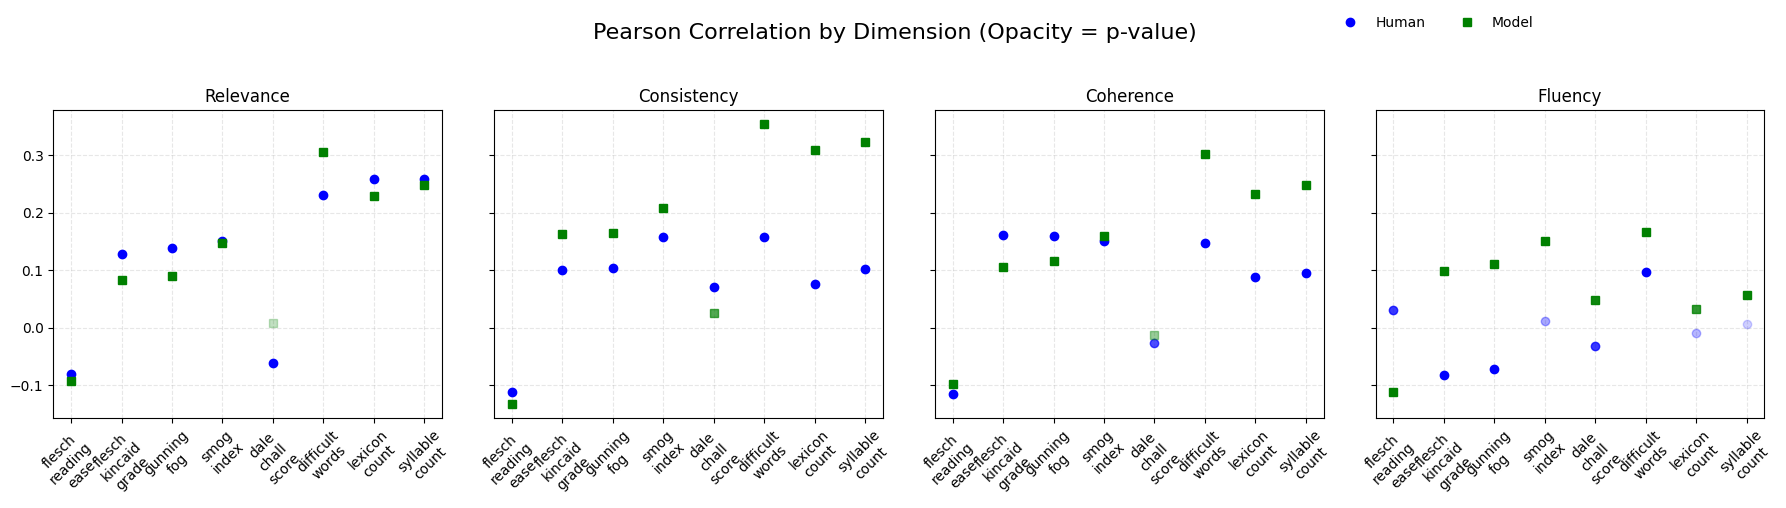

In [93]:
plot_corrs_opacity(df_p,'Pearson')

In [102]:
# plot_corrs_errorbar(df_p,'Pearson')

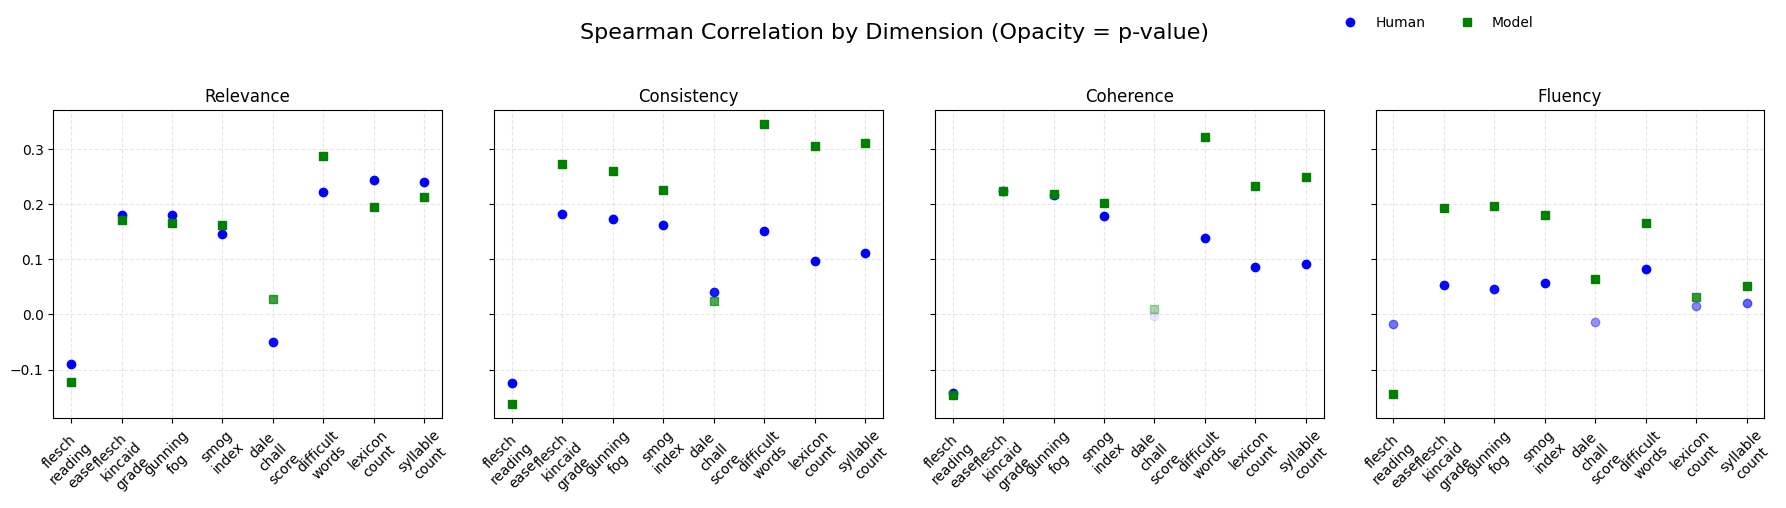

In [95]:
plot_corrs_opacity(df_s,'Spearman')

In [101]:
# plot_corrs_errorbar(df_s,'Spearman')

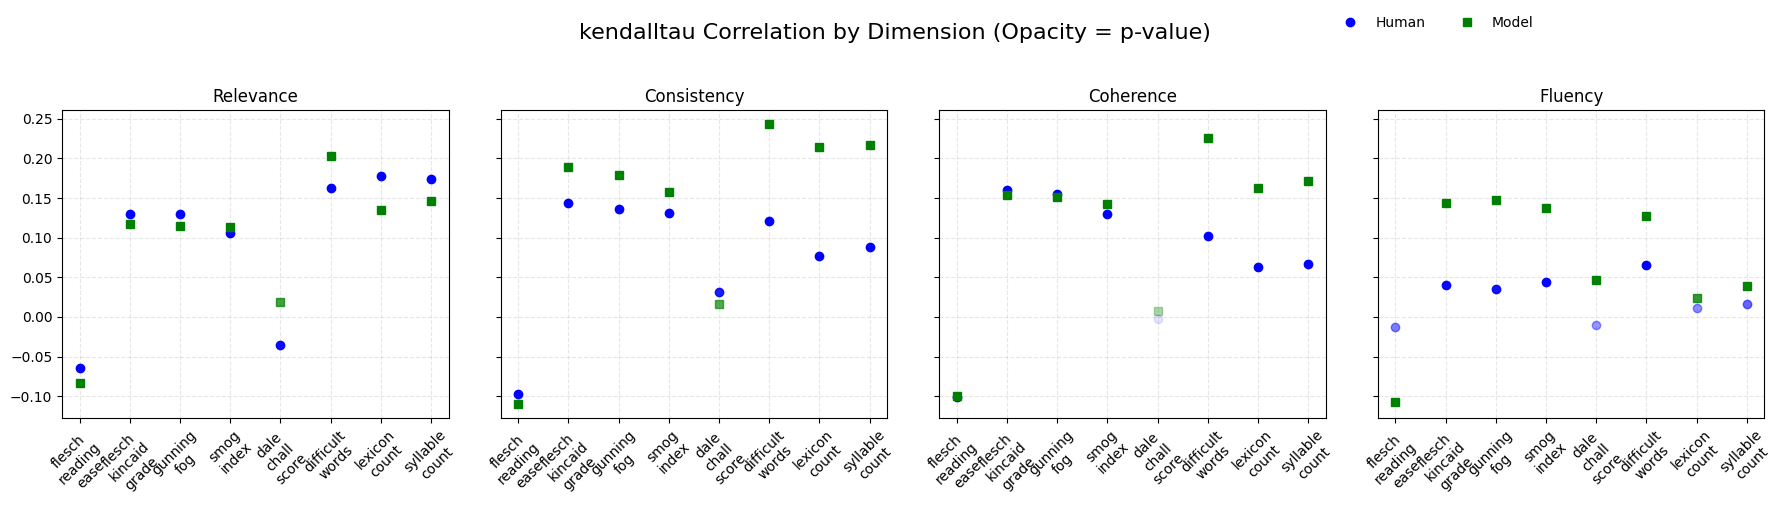

In [97]:
plot_corrs_opacity(df_t,'kendalltau')

In [31]:

def find_significant_red_correlations_dim(
     model_scores, human_scores, red_scores, dim_name, readability_measure='flesch_reading_ease'
):
         results = []

         red_vals, human_vals, model_vals = [], [], []

         for doc_id in red_scores:
            r_list = red_scores[doc_id]
            h_list = human_scores.get(doc_id, [])
            m_list = model_scores.get(doc_id, [])

            if not (len(r_list) == len(h_list) == len(m_list)):
                continue

            for i in range(len(r_list)):
                r_val = r_list[i].get(readability_measure)
                if r_val is None:
                    print('None')
                    continue
                red_vals.append(r_val)
                human_vals.append(h_list[i])
                model_vals.append(m_list[i])

            if len(red_vals) < 2:
                continue  # skip if too little data for correlation
    
            # Compute correlations
            corr_h, pval_h = pearsonr(red_vals, human_vals)
            corr_m, pval_m = pearsonr(red_vals, model_vals)

            print('pval_h',pval_h)
            print('pval_m',pval_m)
            # Collect significant ones
            if pval_h < 0.05:
                results.append((dim_name, 'human', corr_h, pval_h))
            if pval_m < 0.05:
                results.append((dim_name, 'model', corr_m, pval_m))

            return results


In [62]:
readability_metrics = [
    'flesch_reading_ease',
    'flesch_kincaid_grade',
    'gunning_fog',
    'smog_index',
    'dale_chall_score',
    'difficult_words',
    'lexicon_count',
    'syllable_count'
]


In [53]:
metric = 'flesch_kincaid_grade'
res = find_significant_red_correlations_dim(
        model_scores_rel, human_scores_rel, red_scores_rel, 'rel', readability_measure = metric
    )

pval_h 0.21299515218102283
pval_m 0.9422031579178858


In [91]:
from scipy.stats import pearsonr

def find_docwise_significant_readability_correlations(
    dim_name,
    model_scores, human_scores, red_scores,
    readability_measure='flesch_reading_ease'
):
    """
    Computes Pearson correlations between readability and human/model scores
    on a per-document basis.

    Returns a list of significant (p < 0.05) correlations per doc:
    (doc_id, dim_name, 'human'/'model', correlation, p_value)
    """
    results = []

    for doc_id in red_scores:
        r_list = red_scores.get(doc_id, [])
        h_list = human_scores.get(doc_id, [])
        m_list = model_scores.get(doc_id, [])

        if not (len(r_list) == len(h_list) == len(m_list)) or len(r_list) < 2:
            continue

        red_vals, human_vals, model_vals = [], [], []

        for i in range(len(r_list)):
            r_val = r_list[i].get(readability_measure)
            if r_val is None:
                continue
            red_vals.append(r_val)
            human_vals.append(h_list[i])
            model_vals.append(m_list[i])

        if len(red_vals) < 2:
            continue  # not enough paired data for correlation

        # Human vs readability
        corr_h, pval_h = pearsonr(red_vals, human_vals)

        # Model vs readability
        corr_m, pval_m = pearsonr(red_vals, model_vals)

        if pval_h < 0.05:
            results.append((doc_id, dim_name, 'human', corr_h, pval_h, readability_measure))  # 🔸 added field
        if pval_m < 0.05:
            results.append((doc_id, dim_name, 'model', corr_m, pval_m, readability_measure))  # 🔸 added field

    return results


In [92]:
results = find_docwise_significant_readability_correlations(
    dim_name='fluency',
    model_scores=model_scores_flu,
    human_scores=human_scores_flu,
    red_scores=red_scores_flu,
    readability_measure='flesch_reading_ease'
)

/tmp/ipykernel_1271084/97373115.py:39: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_h, pval_h = pearsonr(red_vals, human_vals)


In [96]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

def plot_correlation_with_pvalue_colormap(results):
    # Create DataFrame
    df = pd.DataFrame(results, columns=["doc_id", "dimension", "source", "correlation", "p_value", "readability_measure"])
    df["index"] = range(len(df))

    plt.figure(figsize=(12, 6))

    # Plot with seaborn scatterplot
    scatter = sns.scatterplot(
        data=df,
        x="index",
        y="correlation",
        hue="source",        # Show this in legend 
        size="p_value",      # Do NOT show this in legend 
        palette="deep",
        sizes=(100, 20),
        legend="brief"       # Initially includes both hue + size
    )

    # Remove the size (p_value) legend manually
    handles, labels = scatter.get_legend_handles_labels()
    new_handles = []
    new_labels = []
    for h, l in zip(handles, labels):
        if l in df["source"].unique():  # keep only 'human', 'model', etc.
            new_handles.append(h)
            new_labels.append(l)

    scatter.legend(new_handles, new_labels, title="Source")  # Only 'source' in legend 

    plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.title("Document-wise Correlations Colored by Source, Sized by P-Value")
    plt.xlabel("Document Index")
    plt.ylabel("Pearson Correlation")
    plt.tight_layout()
    plt.show()


In [ ]:
# readability measures
readability_measures = [
    "flesch_reading_ease", "flesch_kincaid_grade", "smog_index",
    "automated_readability_index", "coleman_liau_index", "linsear_write_formula",
    "gunning_fog", "dale_chall"
]

# dimension data
dimension_data = {
    'relevance': (model_scores_rel, human_scores_rel, red_scores_rel),
    'coherence': (model_scores_coh, human_scores_coh, red_scores_coh),
    'fluency':   (model_scores_flu, human_scores_flu, red_scores_flu),
    'consistency': (model_scores_con, human_scores_con, red_scores_con),
}

# Collect all results
all_results = []

for readability_measure in readability_measures:
    for dim_name, (model_scores, human_scores, red_scores) in dimension_data.items():
        results = find_docwise_significant_readability_correlations(
            dim_name=dim_name,
            model_scores=model_scores,
            human_scores=human_scores,
            red_scores=red_scores,
            readability_measure=readability_measure
        )
        
        # Append readability_measure to each result tuple
        results_with_measure = [r + (readability_measure,) for r in results]
        all_results.extend(results_with_measure)_


In [110]:
# Define readability metrics
readability_measures = [
    "flesch_reading_ease", "flesch_kincaid_grade", "smog_index",
    "automated_readability_index", "coleman_liau_index", "linsear_write_formula",
    "gunning_fog", "dale_chall"
]

# Define dimension data
dimension_data = {
    'relevance': (model_scores_rel, human_scores_rel, red_scores_rel),
    'coherence': (model_scores_coh, human_scores_coh, red_scores_coh),
    'fluency':   (model_scores_flu, human_scores_flu, red_scores_flu),
    'consistency': (model_scores_con, human_scores_con, red_scores_con),
}

# Collect all results (optional)
all_results = []

for readability_measure in readability_measures:
    metric_results = []

    for dim_name, (model_scores, human_scores, red_scores) in dimension_data.items():
        results = find_docwise_significant_readability_correlations(
            dim_name=dim_name,
            model_scores=model_scores,
            human_scores=human_scores,
            red_scores=red_scores,
            readability_measure=readability_measure
        )
        metric_results.extend(results)
        all_results.extend(results)

    # # Plot for this readability metric
    # if metric_results:
    #     print(f"Plotting: {readability_measure}")
    #     plot_correlation_with_pvalue_errorbars(metric_results, readability_measure)
    # else:
    #     print(f"No significant results for: {readability_measure}")


/tmp/ipykernel_1271084/97373115.py:39: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_h, pval_h = pearsonr(red_vals, human_vals)


In [111]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_correlation_subplots_4x2(all_results, readability_measures):
    """
    Plot 4x2 subplots — one for each readability metric.
    
    Parameters:
    - all_results: list of (doc_id, dimension, source, correlation, p_value)
    - readability_measures: list of 8 metric names
    """
    # Convert to DataFrame
    df = pd.DataFrame(all_results, columns=["doc_id", "dimension", "source", "correlation", "p_value", "readability_measure"])
    
    fig, axes = plt.subplots(4, 2, figsize=(16, 18))
    axes = axes.flatten()  # make it 1D list for easier indexing

    for i, measure in enumerate(readability_measures):
        ax = axes[i]
        sub_df = df[df["readability_measure"] == measure].copy()
        sub_df["index"] = range(len(sub_df))

        if sub_df.empty:
            ax.set_title(f"{measure} (no data)")
            ax.axis('off')
            continue

        for source in sub_df["source"].unique():
            source_df = sub_df[sub_df["source"] == source]
            ax.errorbar(
                source_df["index"],
                source_df["correlation"],
                yerr=source_df["p_value"],
                fmt='o',
                capsize=4,
                label=source
            )

        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
        ax.set_title(measure)
        ax.set_xlabel("Document Index")
        ax.set_ylabel("Correlation")

        # Only show legend in top-left plot
        if i == 0:
            ax.legend(title="Source")

    # Hide any unused subplot (in case < 8 metrics)
    for j in range(len(readability_measures), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.suptitle("Per-Document Correlations with P-Value Error Bars (4x2 Grid)", fontsize=18, y=1.02)
    plt.show()
